Adaptive Median Filter is used to remove noise, especially Salt and Pepper Noise, from images.

Unlike a normal median filter, its window size changes automatically depending on the noise present in the image.

How it works:
1. Start with an initial window size, such as 3×3.
2. Calculate the minimum, maximum and median pixel values.
3. Check whether the median is between the minimum and maximum values.
4. If it is, check whether the centre pixel is noisy.
5. If the centre pixel is noisy, replace it with the median.
6. If the conditions are not satisfied, increase the window size (5×5, 7×7, etc.).
7. Continue until the maximum window size (Smax) is reached.

2. PSNR (Peak Signal-to-Noise Ratio)
PSNR is used to measure the quality of a denoised image compared with the original clean image.

Higher PSNR generally means better image quality.

Formula:
\[
PSNR=10\log_{10}\left(\frac{MAX^2}{MSE}\right)
\]

Where:
- MAX = Maximum pixel intensity (255 for grayscale).
- MSE = Mean Squared Error.
\[
MSE=\frac{1}{MN}\sum_{i=1}^{M}\sum_{j=1}^{N}
(I(i,j)-K(i,j))^2
\]

Here, I is the original image and K is the denoised image.

Otsu's method is used for image segmentation. It automatically calculates the best threshold value to separate an image into two regions:
- Background
- Foreground
How it works:
1. Read a grayscale image.
2. Calculate its histogram.
3. Check possible threshold values from 0 to 255.
4. Calculate the variance between the two classes.
5. Select the threshold that gives the maximum between-class variance.
6. Convert the grayscale image into a binary image.

In [1]:
pip install numpy pillow matplotlib

Enter initial window size (odd): 3
Enter maximum window size Smax (odd): 3
Median Filter PSNR: 23.971062116966895 dB
Adaptive Median Filter PSNR: 26.29104217837756 dB


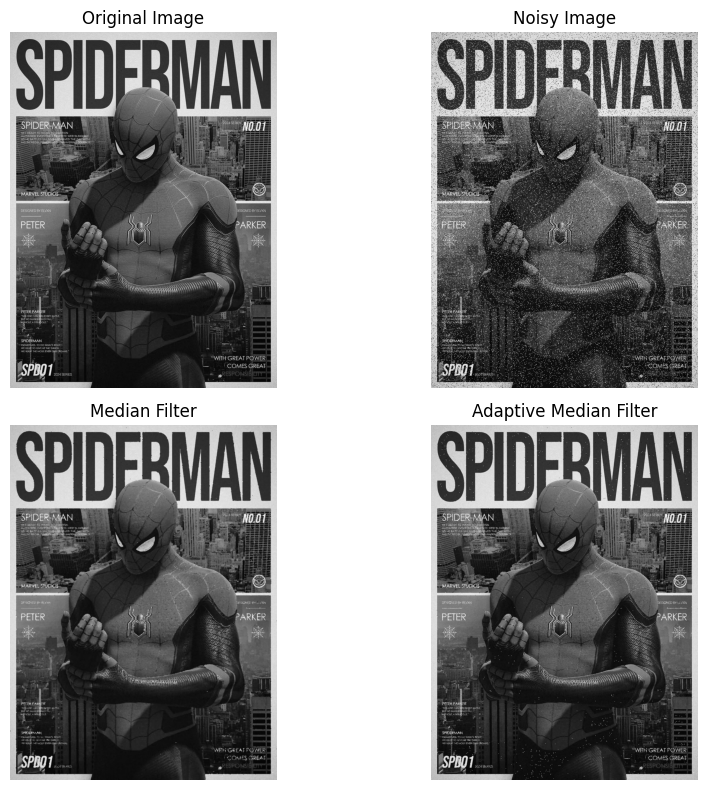

In [2]:

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Read grayscale image
img = np.array(
    Image.open("input.jpg").convert("L"),
    dtype=np.uint8
)

# Add Salt and Pepper noise
def add_noise(image, amount=0.1):
    noisy = image.copy()

    total = image.size
    num = int(amount * total / 2)

    coords = np.random.randint(0, image.shape[0], num), \
             np.random.randint(0, image.shape[1], num)

    noisy[coords] = 0

    coords = np.random.randint(0, image.shape[0], num), \
             np.random.randint(0, image.shape[1], num)

    noisy[coords] = 255

    return noisy


noisy = add_noise(img)


# Take window sizes from user
S = int(input("Enter initial window size (odd): "))
Smax = int(input("Enter maximum window size Smax (odd): "))

if S < 3 or S % 2 == 0 or Smax < S or Smax % 2 == 0:
    raise ValueError("Enter valid odd window sizes, with Smax >= S")


# Padding function
def padding(image, size):
    p = size // 2
    return np.pad(image, p, mode='reflect')


# Normal Median Filter
def median_filter(image, size):
    padded = padding(image, size)
    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            window = padded[i:i+size, j:j+size]
            result[i, j] = np.median(window)

    return result


# Adaptive Median Filter
def adaptive_median(image, S, Smax):
    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            size = S
            output = image[i, j]

            while size <= Smax:

                p = size // 2

                r1 = max(0, i-p)
                r2 = min(image.shape[0], i+p+1)

                c1 = max(0, j-p)
                c2 = min(image.shape[1], j+p+1)

                window = image[r1:r2, c1:c2]

                zmin = np.min(window)
                zmax = np.max(window)
                zmed = np.median(window)
                zxy = image[i, j]

                # Stage A
                if zmin < zmed < zmax:

                    # Stage B
                    if zmin < zxy < zmax:
                        output = zxy
                    else:
                        output = zmed

                    break

                else:
                    size += 2

            result[i, j] = output

    return result


# PSNR calculation
def psnr(original, processed):
    mse = np.mean(
        (original.astype(float) -
         processed.astype(float)) ** 2
    )

    if mse == 0:
        return float('inf')

    return 10 * np.log10((255 ** 2) / mse)


# Apply filters
median_result = median_filter(noisy, S)

adaptive_result = adaptive_median(
    noisy, S, Smax
)


# Calculate PSNR
p1 = psnr(img, median_result)
p2 = psnr(img, adaptive_result)

print("Median Filter PSNR:", p1, "dB")
print("Adaptive Median Filter PSNR:", p2, "dB")


# Display results
images = [
    img, noisy,
    median_result, adaptive_result
]

titles = [
    "Original Image",
    "Noisy Image",
    "Median Filter",
    "Adaptive Median Filter"
]

plt.figure(figsize=(10, 8))

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


Optimal Otsu Threshold: 125


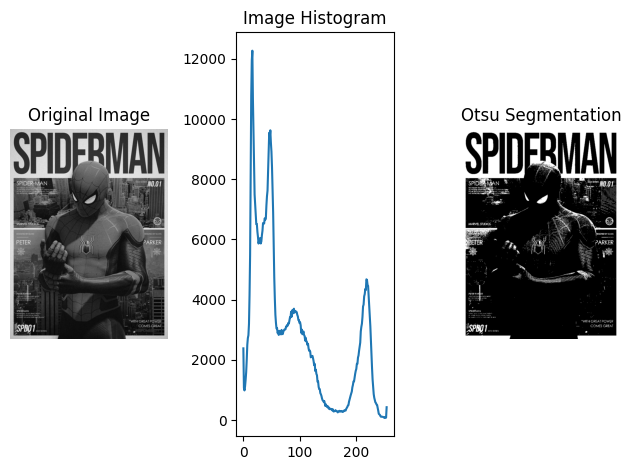

In [3]:

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Read grayscale image
img = np.array(
    Image.open("input.jpg").convert("L")
)

# Calculate histogram
hist = np.zeros(256)

for pixel in img.flatten():
    hist[pixel] += 1

total = img.size

# Calculate total intensity sum
sum_total = np.sum(
    np.arange(256) * hist
)

sum_background = 0
weight_background = 0

max_variance = 0
threshold = 0

# Find optimal threshold
for t in range(256):

    weight_background += hist[t]

    if weight_background == 0:
        continue

    weight_foreground = total - weight_background

    if weight_foreground == 0:
        break

    sum_background += t * hist[t]

    mean_background = (
        sum_background / weight_background
    )

    mean_foreground = (
        sum_total - sum_background
    ) / weight_foreground

    # Between-class variance
    variance = (
        weight_background *
        weight_foreground *
        (mean_background - mean_foreground) ** 2
    )

    if variance > max_variance:
        max_variance = variance
        threshold = t


# Apply threshold
binary = np.where(
    img > threshold, 255, 0
).astype(np.uint8)

print("Optimal Otsu Threshold:", threshold)

# Display results
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.plot(hist)
plt.title("Image Histogram")

plt.subplot(1, 3, 3)
plt.imshow(binary, cmap='gray')
plt.title("Otsu Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()


In [4]:
pip install opencv-python numpy matplotlib

Enter initial window size (odd, e.g. 3): 3
Enter maximum window size Smax (odd, e.g. 7): 7
Median Filter PSNR: 23.9853519066872 dB
Adaptive Median Filter PSNR: 27.521786799086403 dB


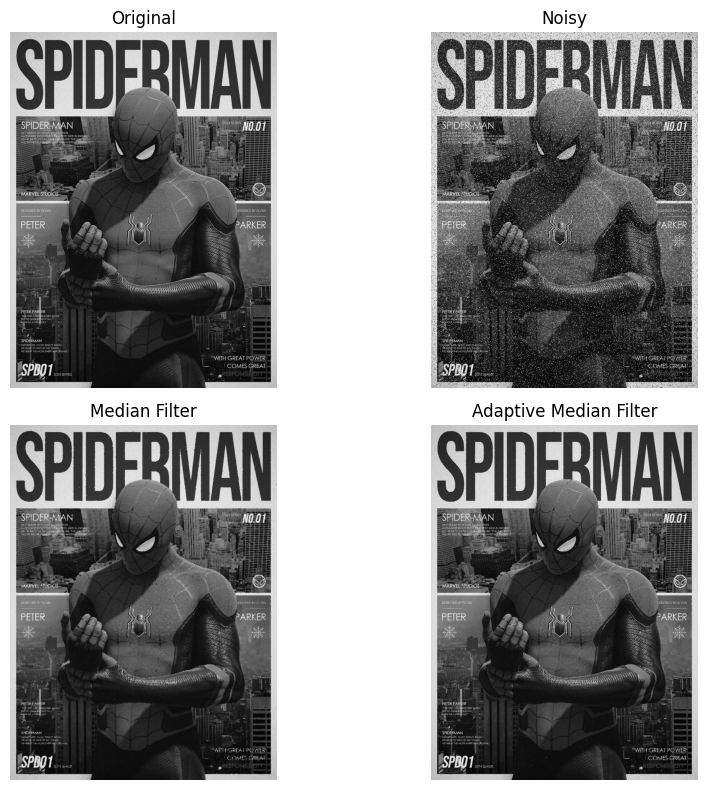

In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("input.jpg", 0)

# Add Salt and Pepper noise
def add_noise(image, amount=0.1):
    noisy = image.copy()

    num = int(amount * image.size / 2)

    coords = (
        np.random.randint(0, image.shape[0], num),
        np.random.randint(0, image.shape[1], num)
    )

    noisy[coords] = 0

    coords = (
        np.random.randint(0, image.shape[0], num),
        np.random.randint(0, image.shape[1], num)
    )

    noisy[coords] = 255

    return noisy


noisy = add_noise(img)

# Input window sizes
S = int(input("Enter initial window size: "))
Smax = int(input("Enter maximum window size Smax: "))

if S < 3 or S % 2 == 0 or Smax < S or Smax % 2 == 0:
    raise ValueError("Window sizes must be odd and Smax >= S")


# Median Filter
median = cv2.medianBlur(noisy, S)


# Adaptive Median Filter
def adaptive_median(image, S, Smax):

    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            size = S
            output = image[i, j]

            while size <= Smax:

                p = size // 2

                r1 = max(0, i-p)
                r2 = min(image.shape[0], i+p+1)

                c1 = max(0, j-p)
                c2 = min(image.shape[1], j+p+1)

                window = image[r1:r2, c1:c2]

                zmin = np.min(window)
                zmax = np.max(window)
                zmed = np.median(window)
                zxy = image[i, j]

                # Stage A
                if zmin < zmed < zmax:

                    # Stage B
                    if zmin < zxy < zmax:
                        output = zxy
                    else:
                        output = zmed

                    break

                else:
                    size += 2

            result[i, j] = output

    return result


adaptive = adaptive_median(noisy, S, Smax)


# PSNR function
def psnr(original, processed):

    mse = np.mean(
        (original.astype(float) -
         processed.astype(float)) ** 2
    )

    if mse == 0:
        return float('inf')

    return 10 * np.log10(255**2 / mse)


# Compare PSNR
print("Median Filter PSNR:",
      psnr(img, median), "dB")

print("Adaptive Median Filter PSNR:",
      psnr(img, adaptive), "dB")


# Display results
images = [img, noisy, median, adaptive]

titles = [
    "Original",
    "Noisy",
    "Median Filter",
    "Adaptive Median Filter"
]

plt.figure(figsize=(10, 8))

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


Optimal Threshold: 125.0


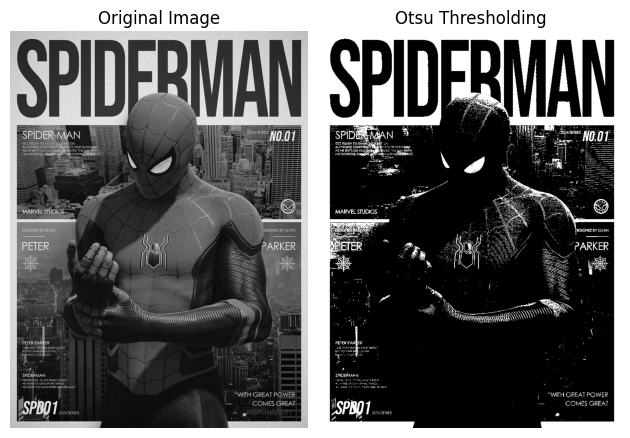

In [8]:

import cv2
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("input.jpg", 0)

# Apply Otsu's thresholding
threshold, binary = cv2.threshold(
    img,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Print threshold value
print("Optimal Threshold:", threshold)

# Display images
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap='gray')
plt.title("Otsu Thresholding")
plt.axis("off")

plt.tight_layout()
plt.show()
